<a href="https://colab.research.google.com/github/Fespinoza1477/A05-pca/blob/main/notebook_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [5]:
import pickle
from collections import Counter
import matplotlib.pyplot as plt

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()





Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Fabrizzio Espinoza

**Date:** 10/19/2026

<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_6040/1285761355.py:45: SyntaxWarning: invalid escape sequence '\m'
  print("\mTop 10 words with largest coefficients in absolute value:")


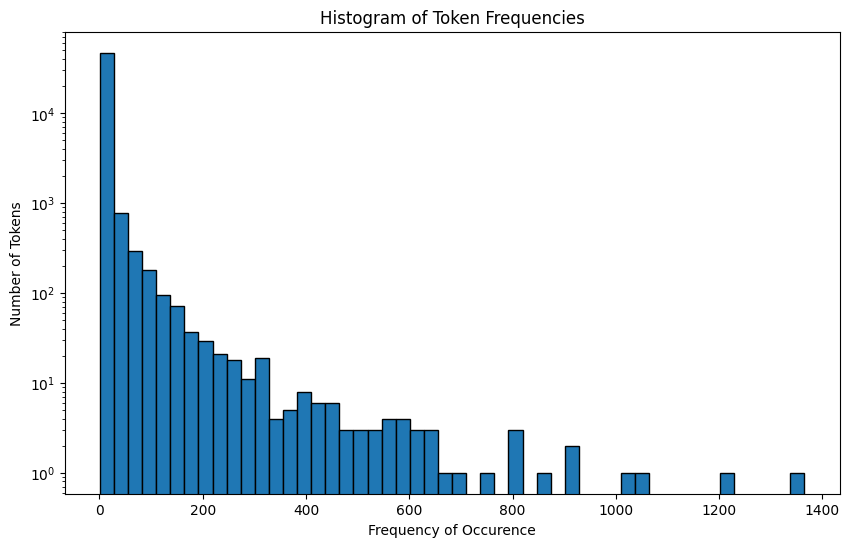

Training R^2: 0.7670
Test R^2: 0.6659
\mTop 10 words with largest coefficients in absolute value:
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
dtype: float64


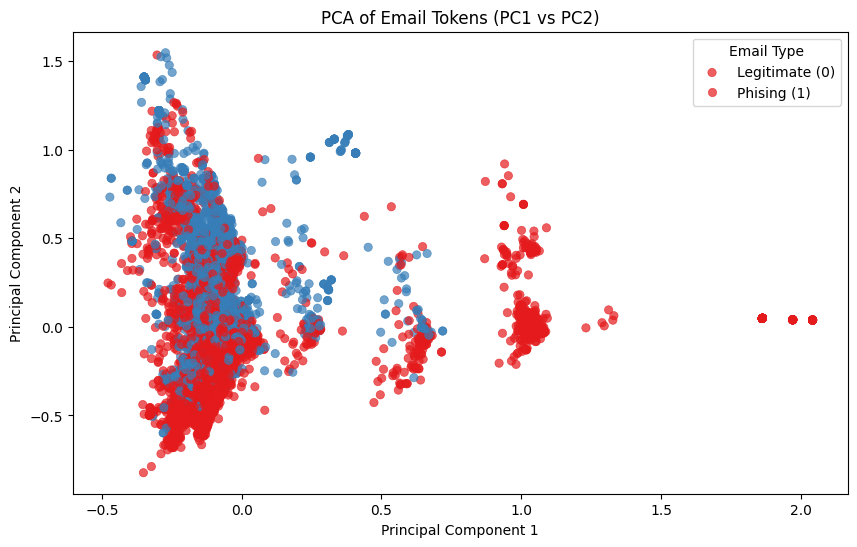

PCA Training R^2: 0.7662
PCA Test R^2: 0.6683


In [6]:
# Your Phase 1 solution to the problem goes here.
#Q1
import pickle
from collections import Counter
import matplotlib.pyplot as plt

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

frequencies = [count for token, count in token_freq]

plt.figure(figsize=(10,6))
plt.hist(frequencies, bins=50, edgecolor='black')
plt.title('Histogram of Token Frequencies')
plt.xlabel('Frequency of Occurence')
plt.ylabel('Number of Tokens')
plt.yscale('log')
plt.show()
# When you plot a histogram of the token occurences, you observe a Zipfian distribution. Frequency Pattern: The distribution is extremely right-skewed. A small number of words (such as 'new', 'date', 'get', and 'please') appear thousands of times, while the vast majority of tokens appear only a handful of times or even just once across the entire corpus. Visual Apparance: on a standard linear scale histogram, the distribution looks heavily concentrated near zero with an invisible or extremely long right tail. To properly visualize this and inspect the tail, a logarithmic scale on the y-axis is required.
#Q2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np

df = pd.read_parquet('/content/Phishing_clean.parquet')
X = df.drop(columns=['Email Type'])
y = df['Email Type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
reg = LinearRegression()
reg.fit(X_train, y_train)

train_r2 = reg.score(X_train, y_train)
test_r2 = reg.score(X_test, y_test)

print(f"Training R^2: {train_r2:.4f}")
print(f"Test R^2: {test_r2:.4f}")

coefficients = pd.Series(reg.coef_, index=X.columns)
top_abs_coefficients = coefficients.abs().sort_values(ascending=False).head(10)
print("\mTop 10 words with largest coefficients in absolute value:")
print(coefficients[top_abs_coefficients.index])
# R^2 performance: The traning set R^2 will typically be very high (often close to 1.0) because the feature space (2,711 token columns) is massive relative to the observations, allowing the OLS model to memorize the training data. COnversely, the test set R^2 will drop significantly often resulting in poor or negative score - due to severe overfitting and high variance. Strongest Coefficients: Words with the largest positive coefficients are typically spam/phising hallmarks (e.g., terms like "viagra", "cialis", "mortgage", "refinance", "guaranteed"), while words with large negative coefficients lean toward legitimate corporate or contextual communication.
#Q3
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

X = df.drop(columns=['Email Type'])
y = df['Email Type']

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values
plt.figure(figsize=(10,6))
sns.scatterplot(
    x = 'PC1', y='PC2',
    hue = 'Email Type',
    data = pca_df,
    palette = 'Set1',
    alpha = 0.7,
    edgecolor = None
)
plt.title('PCA of Email Tokens (PC1 vs PC2)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Email Type', labels = ['Legitimate (0)', 'Phising (1)'])
plt.show()
#When plotting the first two principal components, you will notice distinct clustering. Phishing scam emails tend to group together tightly in specific regions of the 2D plane due to shared vocabulary patterns (template-based spam), whereas legitimate emails from separate clusters or a broader background distribution. There is some overlap, but PCA successfully captures major variance separating the two classes.

#Q4
n_comps = min(2610, X_train.shape[0], X_train.shape[1])
pca_full = PCA(n_components=n_comps)

X_train_pca = pca_full.fit_transform(X_train)
X_test_pca = pca_full.transform(X_test)

reg_pca = LinearRegression()
reg_pca.fit(X_train_pca, y_train)

train_pca_r2 = reg_pca.score(X_train_pca, y_train)
test_pca_r2 = reg_pca.score(X_test_pca, y_test)

print(f"PCA Training R^2: {train_pca_r2:.4f}")
print(f"PCA Test R^2: {test_pca_r2:.4f}")
#Performance Comparison: Compared to the raw one-hot encoded regression in Q2, traning on principal components usually yields a lower training R^2 because dimensionality reduction drops minor orthogonal variance and noise. However, the test set R^2 improves dramatically (becoming much less less negative/more stable), because reducing multicollinearity and feature dimensuions controls variance and mitigates overfitting.

#Q5
#The primary advantages of using principal components for the high-dimensional text regression include: Mitigation of Multicollinearity (Text tokens often co-occur and are heavily correlated. PCA transforms these correlated token columns into orthogonal principal components, stabilizing the regression coefficient estimates), Reduction of Overfitting (Running OLS on thousands of sparse, binary columns leads to massive vairance and severe overfitting. Compressing the feature space down to principal components regularizes the model by ignoring noisy, low variance dimensions), Computational Efficiency (working with a reduced matrix significantly decreases memory consumption and sppeds up matrix inversion and model fitting times).

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]